# HAR Results: Colab vs Laptop

This notebook compares the Human Activity Recognition (HAR) training and inference measurements in `colab_har` and `laptop_har`. It produces reproducible tables, comparison plots, and a descriptive conclusion from the CSVs.

**Interpretation and limitations.** Training files contain 100 epoch records but only one seed per model and environment; they are one training trace, not 100 independent trials. Inference files contain five repeated measurements for each model and batch size (1, 16, 64, and 256). The notebook reports inference means and standard deviations across those five repeats, but does not claim statistical significance. Inference energy comparisons use **gross joules per item**; idle-subtracted energy can be negative in these measurements and is not suitable for a physical energy comparison. Results describe these recorded runs and should not be generalized to all hardware or Colab configurations.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

plt.style.use("seaborn-v0_8-whitegrid")
ENV_DIRS = {"Colab": Path("colab_har"), "Laptop": Path("laptop_har")}

# Find the project root whether the notebook is run from the project folder or its parent.
candidates = [Path.cwd(), Path.cwd().parent]
PROJECT_ROOT = next(
    (root for root in candidates if all((root / d).is_dir() for d in ENV_DIRS.values())),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError(
        "Could not locate colab_har and laptop_har. Run this notebook from the project "
        "directory or update PROJECT_ROOT to the directory containing both folders."
    )
print(f"Project root: {PROJECT_ROOT.resolve()}")

Project root: C:\Users\vaikr\Documents\Python\afml_paper


In [2]:
train_frames = []
infer_frames = []
for environment, folder in ENV_DIRS.items():
    train_path = PROJECT_ROOT / folder / "har_train_all_models_5trials.csv"
    infer_path = PROJECT_ROOT / folder / "har_infer_all_models_5trials.csv"
    if not train_path.is_file() or not infer_path.is_file():
        raise FileNotFoundError(f"Expected training and inference CSVs under {PROJECT_ROOT / folder}")
    train = pd.read_csv(train_path)
    infer = pd.read_csv(infer_path)
    train["environment"] = environment
    infer["environment"] = environment
    train_frames.append(train)
    infer_frames.append(infer)

training = pd.concat(train_frames, ignore_index=True)
inference = pd.concat(infer_frames, ignore_index=True)

required_train = {"environment", "model", "epoch", "seed", "train_time_s", "train_energy_j_gross", "val_acc", "test_acc"}
required_infer = {"environment", "model", "trial", "batch_size", "duration_s", "items_per_s", "j_per_item_gross"}
if missing := required_train - set(training.columns):
    raise ValueError(f"Training CSVs are missing required columns: {sorted(missing)}")
if missing := required_infer - set(inference.columns):
    raise ValueError(f"Inference CSVs are missing required columns: {sorted(missing)}")

training_coverage = training.groupby(["environment", "model"]).agg(
    epoch_records=("epoch", "size"), seeds=("seed", "nunique"),
).reset_index()
inference_coverage = inference.groupby(["environment", "model", "batch_size"]).agg(
    rows=("trial", "size"), repeats=("trial", "nunique"),
).reset_index()
print("Training coverage (epoch records are not independent runs):")
display(training_coverage)
print("Inference coverage (one row per model, batch size, and repeat):")
display(inference_coverage)

Training coverage (epoch records are not independent runs):


,environment,model,epoch_records,seeds
0,Colab,cfc,100,1
1,Colab,lstm,100,1
2,Colab,transformer,100,1
3,Laptop,cfc,100,1
4,Laptop,lstm,100,1
5,Laptop,transformer,100,1


Inference coverage (one row per model, batch size, and repeat):


,environment,model,batch_size,rows,repeats
0,Colab,cfc,1,5,5
1,Colab,cfc,16,5,5
2,Colab,cfc,64,5,5
3,Colab,cfc,256,5,5
4,Colab,lstm,1,5,5
5,Colab,lstm,16,5,5
6,Colab,lstm,64,5,5
7,Colab,lstm,256,5,5
8,Colab,transformer,1,5,5
9,Colab,transformer,16,5,5


In [3]:
# The last recorded epoch contains cumulative run time/energy and final accuracy.
training = training.copy()
training["epoch"] = pd.to_numeric(training["epoch"], errors="coerce")
train_summary = (
    training.sort_values("epoch")
    .groupby(["environment", "model"], as_index=False)
    .tail(1)
    .rename(columns={
        "train_time_s": "training_time_s",
        "train_energy_j_gross": "training_energy_j_gross",
        "val_acc": "final_val_accuracy",
        "test_acc": "final_test_accuracy",
    })[["environment", "model", "seed", "epoch", "training_time_s", "training_energy_j_gross", "final_val_accuracy", "final_test_accuracy"]]
    .sort_values(["model", "environment"])
    .reset_index(drop=True)
)

for column in ["duration_s", "items_per_s", "j_per_item_gross", "avg_power_w", "energy_j_net"]:
    if column in inference.columns:
        inference[column] = pd.to_numeric(inference[column], errors="coerce")
inference_summary = (
    inference.groupby(["environment", "model", "batch_size"], as_index=False)
    .agg(
        repeats=("trial", "nunique"),
        throughput_mean_items_s=("items_per_s", "mean"),
        throughput_sd_items_s=("items_per_s", "std"),
        gross_j_per_item_mean=("j_per_item_gross", "mean"),
        gross_j_per_item_sd=("j_per_item_gross", "std"),
        inference_duration_mean_s=("duration_s", "mean"),
    )
    .sort_values(["model", "batch_size", "environment"])
    .reset_index(drop=True)
)

print("Training summary (one trace per environment/model):")
display(train_summary.round(4))
print("Inference summary (mean and sample SD over recorded repeats):")
display(inference_summary.round(4))
if "energy_j_net" in inference:
    negative_net = inference.loc[inference["energy_j_net"] < 0, ["environment", "model", "batch_size", "trial", "energy_j_net"]]
    if not negative_net.empty:
        print("\nIdle-subtracted inference energy contains negative observations; gross energy is used below:")
        display(negative_net)

Training summary (one trace per environment/model):


,environment,model,seed,epoch,training_time_s,training_energy_j_gross,final_val_accuracy,final_test_accuracy
0,Colab,cfc,0,100,1611.9405,53891.8424,0.7233,0.6759
1,Laptop,cfc,0,100,6117.3949,70319.1282,0.6751,0.6410
2,Colab,lstm,0,100,113.5788,7466.2212,0.8536,0.8904
3,Laptop,lstm,0,100,109.9229,5488.6143,0.8518,0.8985
4,Colab,transformer,0,100,77.7778,5111.2793,0.8820,0.9053
5,Laptop,transformer,0,100,186.1166,6432.0166,0.8789,0.8996


Inference summary (mean and sample SD over recorded repeats):


,environment,model,batch_size,repeats,throughput_mean_items_s,throughput_sd_items_s,gross_j_per_item_mean,gross_j_per_item_sd,inference_duration_mean_s
0,Colab,cfc,1,5,21.6833,0.8052,1.7044,0.0649,20.0243
1,Laptop,cfc,1,5,5.0224,0.2107,1.0944,0.0427,20.1091
2,Colab,cfc,16,5,347.1023,13.4748,0.1078,0.0042,20.0238
3,Laptop,cfc,16,5,80.5652,4.9348,0.0700,0.0040,20.0578
4,Colab,cfc,64,5,1382.1761,34.7221,0.0274,0.0007,20.0216
5,Laptop,cfc,64,5,293.3181,12.6874,0.0208,0.0024,20.1618
6,Colab,cfc,256,5,5430.2024,118.4054,0.0073,0.0002,20.0268
7,Laptop,cfc,256,5,1247.5662,46.4119,0.0048,0.0002,20.1094
8,Colab,lstm,1,5,979.7097,6.7432,0.0566,0.0004,20.0006
9,Laptop,lstm,1,5,741.3723,16.5407,0.0387,0.0012,20.0008



Idle-subtracted inference energy contains negative observations; gross energy is used below:


,environment,model,batch_size,trial,energy_j_net
80,Laptop,transformer,1,0,-60.444688
81,Laptop,transformer,1,1,-36.075222
82,Laptop,transformer,1,2,-63.750076
83,Laptop,transformer,1,3,-37.624218
84,Laptop,transformer,1,4,-63.851284
100,Laptop,cfc,1,0,-67.011135
101,Laptop,cfc,1,1,-68.550464
102,Laptop,cfc,1,2,-68.120723
103,Laptop,cfc,1,3,-66.959126
104,Laptop,cfc,1,4,-67.345304


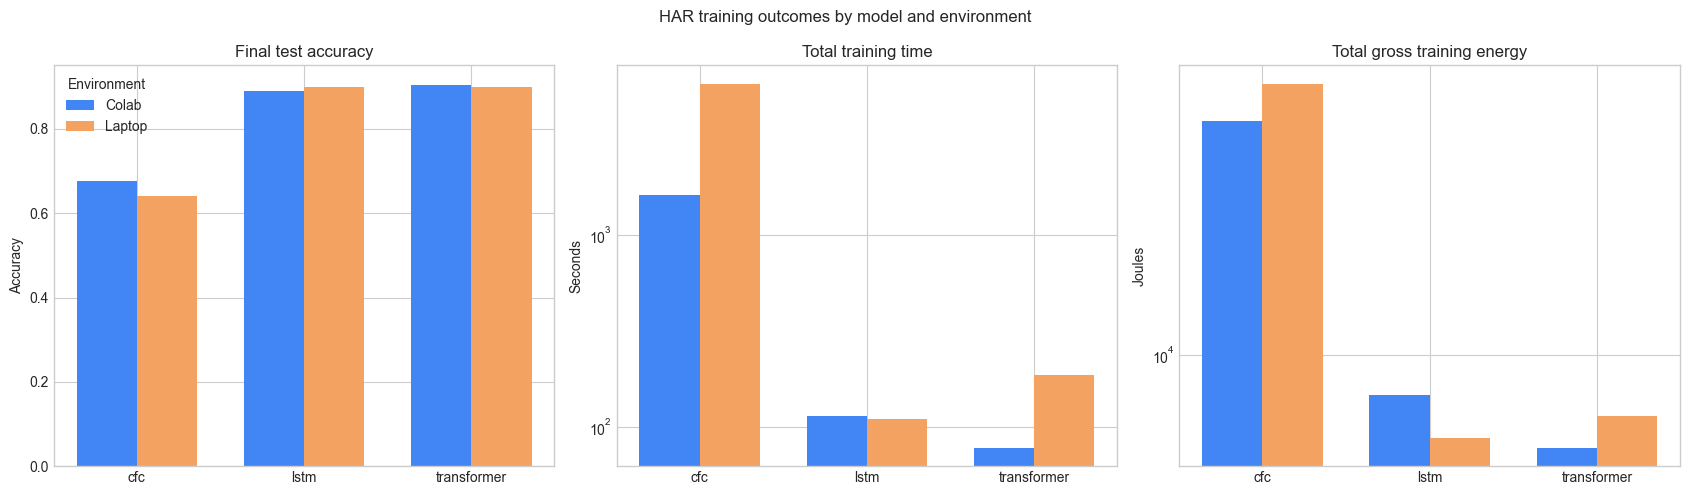

In [4]:
models = sorted(training["model"].dropna().unique())
colors = {"Colab": "#4285F4", "Laptop": "#F4A261"}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
plot_specs = [
    ("final_test_accuracy", "Final test accuracy", "Accuracy", False),
    ("training_time_s", "Total training time", "Seconds", True),
    ("training_energy_j_gross", "Total gross training energy", "Joules", True),
]
x = np.arange(len(models))
width = 0.36
for axis, (metric, title, ylabel, log_scale) in zip(axes, plot_specs):
    for offset, environment in zip([-width / 2, width / 2], ["Colab", "Laptop"]):
        values = (train_summary[train_summary["environment"] == environment]
                  .set_index("model")[metric].reindex(models))
        axis.bar(x + offset, values, width, label=environment, color=colors[environment])
    axis.set(title=title, ylabel=ylabel, xticks=x, xticklabels=models)
    if log_scale:
        axis.set_yscale("log")
axes[0].legend(title="Environment")
fig.suptitle("HAR training outcomes by model and environment")
fig.tight_layout()
plt.show()

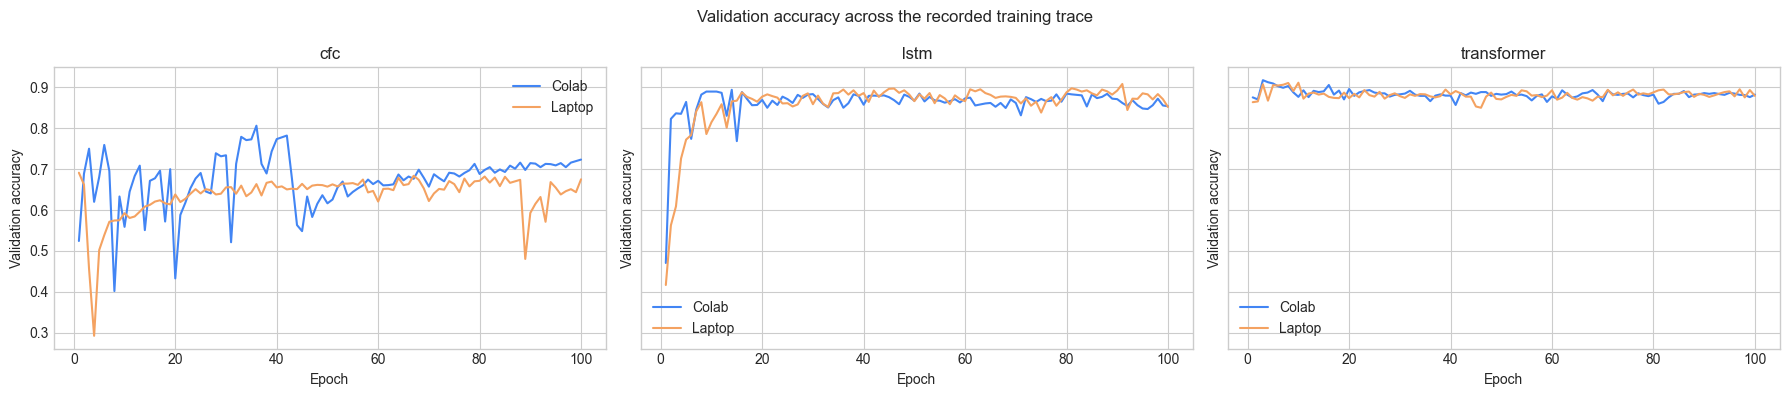

In [5]:
fig, axes = plt.subplots(1, len(models), figsize=(6 * len(models), 4), sharey=True)
if len(models) == 1:
    axes = [axes]
for axis, model in zip(axes, models):
    for environment in ["Colab", "Laptop"]:
        curve = training[(training["model"] == model) & (training["environment"] == environment)].sort_values("epoch")
        axis.plot(curve["epoch"], curve["val_acc"], label=environment, color=colors[environment])
    axis.set(title=model, xlabel="Epoch", ylabel="Validation accuracy")
    axis.legend()
fig.suptitle("Validation accuracy across the recorded training trace")
fig.tight_layout()
plt.show()

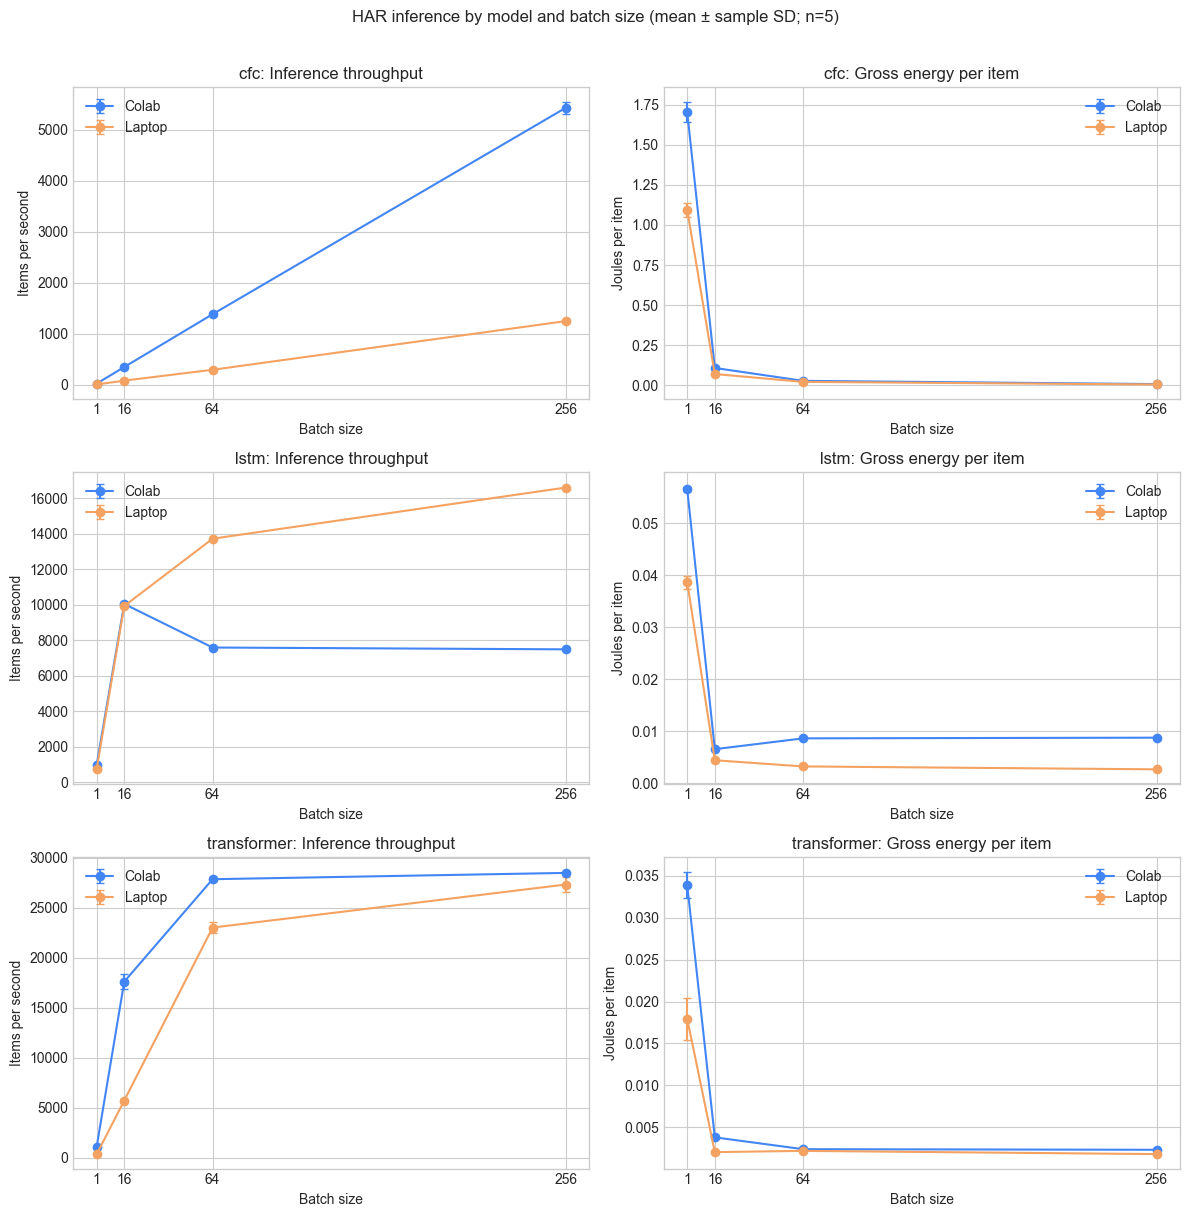

In [6]:
batch_sizes = sorted(inference_summary["batch_size"].unique())
fig, axes = plt.subplots(len(models), 2, figsize=(12, 4 * len(models)), squeeze=False)
for row, model in enumerate(models):
    for column, metric, sd_metric, title, ylabel in [
        (0, "throughput_mean_items_s", "throughput_sd_items_s", "Inference throughput", "Items per second"),
        (1, "gross_j_per_item_mean", "gross_j_per_item_sd", "Gross energy per item", "Joules per item"),
    ]:
        axis = axes[row, column]
        for environment in ["Colab", "Laptop"]:
            subset = inference_summary[(inference_summary["model"] == model) &
                                       (inference_summary["environment"] == environment)].set_index("batch_size").reindex(batch_sizes)
            axis.errorbar(batch_sizes, subset[metric], yerr=subset[sd_metric], marker="o",
                          capsize=3, label=environment, color=colors[environment])
        axis.set(title=f"{model}: {title}", xlabel="Batch size", ylabel=ylabel, xticks=batch_sizes)
        axis.legend()
fig.suptitle("HAR inference by model and batch size (mean ± sample SD; n=5)", y=1.01)
fig.tight_layout()
plt.show()

In [8]:
def value(environment, model, frame, column, batch_size=None):
    mask = (frame["environment"] == environment) & (frame["model"] == model)
    if batch_size is not None:
        mask &= frame["batch_size"] == batch_size
    row = frame[mask]
    return float(row.iloc[0][column])

paragraphs = []
for model in models:
    colab_acc = value("Colab", model, train_summary, "final_test_accuracy")
    laptop_acc = value("Laptop", model, train_summary, "final_test_accuracy")
    colab_time = value("Colab", model, train_summary, "training_time_s")
    laptop_time = value("Laptop", model, train_summary, "training_time_s")
    colab_energy = value("Colab", model, train_summary, "training_energy_j_gross")
    laptop_energy = value("Laptop", model, train_summary, "training_energy_j_gross")
    time_winner = "Colab" if colab_time < laptop_time else "Laptop"
    energy_winner = "Colab" if colab_energy < laptop_energy else "Laptop"
    paragraphs.append(
        f"For **{model}**, final test accuracy was {colab_acc:.3f} on Colab and {laptop_acc:.3f} on the laptop. "
        f"Recorded training was faster on {time_winner} ({colab_time:.1f} s vs {laptop_time:.1f} s) "
        f"and used less gross training energy on {energy_winner} ({colab_energy:.0f} J vs {laptop_energy:.0f} J)."
    )
    for batch_size in batch_sizes:
        colab_rate = value("Colab", model, inference_summary, "throughput_mean_items_s", batch_size)
        laptop_rate = value("Laptop", model, inference_summary, "throughput_mean_items_s", batch_size)
        colab_j_item = value("Colab", model, inference_summary, "gross_j_per_item_mean", batch_size)
        laptop_j_item = value("Laptop", model, inference_summary, "gross_j_per_item_mean", batch_size)
        rate_winner = "Colab" if colab_rate > laptop_rate else "Laptop"
        item_energy_winner = "Colab" if colab_j_item < laptop_j_item else "Laptop"
        paragraphs.append(
            f"At batch size {batch_size}, **{model}** inference throughput was higher on {rate_winner} "
            f"({colab_rate:.1f} vs {laptop_rate:.1f} items/s), while gross energy per item was lower on "
            f"{item_energy_winner} ({colab_j_item:.4f} vs {laptop_j_item:.4f} J/item; Colab vs laptop)."
        )

conclusion = (
    "## Descriptive conclusion\n\n"
    "On the recorded HAR runs, the relative performance and energy trade-offs differed by model and compute environment.\n\n"
    + "\n\n".join(paragraphs)
    + "\n\nThese observations are descriptive, not inferential: the training comparison is based on a single recorded "
    "seed/run per model and environment, while each inference model/batch-size estimate summarizes five repeats. No statistical significance "
    "or population-level hardware claim is warranted from these data alone. Gross inference energy is reported because "
    "the supplied idle-subtracted energy is negative in some observations. Accuracy values are taken from the final "
    "recorded epoch; training duration and energy are cumulative CSV fields."
)
display(Markdown(conclusion))

## Descriptive conclusion

On the recorded HAR runs, the relative performance and energy trade-offs differed by model and compute environment.

For **cfc**, final test accuracy was 0.676 on Colab and 0.641 on the laptop. Recorded training was faster on Colab (1611.9 s vs 6117.4 s) and used less gross training energy on Colab (53892 J vs 70319 J).

At batch size 1, **cfc** inference throughput was higher on Colab (21.7 vs 5.0 items/s), while gross energy per item was lower on Laptop (1.7044 vs 1.0944 J/item; Colab vs laptop).

At batch size 16, **cfc** inference throughput was higher on Colab (347.1 vs 80.6 items/s), while gross energy per item was lower on Laptop (0.1078 vs 0.0700 J/item; Colab vs laptop).

At batch size 64, **cfc** inference throughput was higher on Colab (1382.2 vs 293.3 items/s), while gross energy per item was lower on Laptop (0.0274 vs 0.0208 J/item; Colab vs laptop).

At batch size 256, **cfc** inference throughput was higher on Colab (5430.2 vs 1247.6 items/s), while gross energy per item was lower on Laptop (0.0073 vs 0.0048 J/item; Colab vs laptop).

For **lstm**, final test accuracy was 0.890 on Colab and 0.899 on the laptop. Recorded training was faster on Laptop (113.6 s vs 109.9 s) and used less gross training energy on Laptop (7466 J vs 5489 J).

At batch size 1, **lstm** inference throughput was higher on Colab (979.7 vs 741.4 items/s), while gross energy per item was lower on Laptop (0.0566 vs 0.0387 J/item; Colab vs laptop).

At batch size 16, **lstm** inference throughput was higher on Colab (10047.6 vs 9933.8 items/s), while gross energy per item was lower on Laptop (0.0066 vs 0.0045 J/item; Colab vs laptop).

At batch size 64, **lstm** inference throughput was higher on Laptop (7594.7 vs 13723.5 items/s), while gross energy per item was lower on Laptop (0.0087 vs 0.0033 J/item; Colab vs laptop).

At batch size 256, **lstm** inference throughput was higher on Laptop (7491.8 vs 16608.8 items/s), while gross energy per item was lower on Laptop (0.0088 vs 0.0027 J/item; Colab vs laptop).

For **transformer**, final test accuracy was 0.905 on Colab and 0.900 on the laptop. Recorded training was faster on Colab (77.8 s vs 186.1 s) and used less gross training energy on Colab (5111 J vs 6432 J).

At batch size 1, **transformer** inference throughput was higher on Colab (1079.7 vs 348.5 items/s), while gross energy per item was lower on Laptop (0.0339 vs 0.0179 J/item; Colab vs laptop).

At batch size 16, **transformer** inference throughput was higher on Colab (17611.3 vs 5725.6 items/s), while gross energy per item was lower on Laptop (0.0038 vs 0.0020 J/item; Colab vs laptop).

At batch size 64, **transformer** inference throughput was higher on Colab (27855.7 vs 23018.9 items/s), while gross energy per item was lower on Laptop (0.0024 vs 0.0022 J/item; Colab vs laptop).

At batch size 256, **transformer** inference throughput was higher on Colab (28487.7 vs 27327.0 items/s), while gross energy per item was lower on Laptop (0.0023 vs 0.0018 J/item; Colab vs laptop).

These observations are descriptive, not inferential: the training comparison is based on a single recorded seed/run per model and environment, while each inference model/batch-size estimate summarizes five repeats. No statistical significance or population-level hardware claim is warranted from these data alone. Gross inference energy is reported because the supplied idle-subtracted energy is negative in some observations. Accuracy values are taken from the final recorded epoch; training duration and energy are cumulative CSV fields.